# 08 · ESRI: contagion features, and a second model from the tool comparison

Notebook 06 found the deployed method's weakness: it puts change on the right pixels
within a neighbourhood, but not in the right regions. Beyond 1–2 km it is no better than
random placement. The neighbourhood rule, which only looks at where classes already are,
keeps up with random placement to 2 km.

**The idea.** In deforestation studies, clearing is *contagious*: forest near recent
clearings and roads is cleared sooner (Rosa et al. 2013). The deployed method already has
the distance to roads. What it lacks is where **genuinely new change** happened recently.
Notebook 06's history features describe only each pixel's *own* past, which is why they
predict pixels going back to an earlier class.

**Same design and rule as notebooks 06–07:** ESRI on the deployed 250 m grid, Guinea only,
the observed quantity of each transition, the deployed allocator. Settings chosen on
**2023→2024**, tested once on **2024→2025**. Score: the Figure of Merit over all change. A
configuration improves on the deployed method when it gains on 2023→2024 and again on
2024→2025 by more than the spread across seeds, beats random placement (Pontius et al. 2004;
Bouthillier et al. 2021), and passes the flip-back check of notebook 06: its new-change FoM is
not lower than the deployed method's.

In [1]:
import sys; sys.path.insert(0, "../scripts")              # shared code: landuse_experiments/scripts/
import nb_helpers as H
import esri_methods as E
import esri_seasonal as ES
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": H.SURFACE})
RERUN = False
PH = ("validation", "test")
LABEL = {"validation": "2023→2024 (choose)", "test": "2024→2025 (test)"}
prof = E.grid(); g = H.guinea_mask(prof)

def get(tag, phase, runner):
    r = None if RERUN else E.load_result(tag, phase)
    return r if r else runner()

def predicted(tag, phase, mode="Expander-only"):
    return H.read_tif(E.RUNS / tag / phase / "allocation" / mode.replace(" ", "_") / "predicted_land_cover.tif")[0]

def kinds(tag, phase):
    """All-change FoM ("FoM") and the flip-back check ("new") of one saved forecast."""
    _, ts, tf = E.phase_years(phase)
    return E.change_kind_scores(ts, E.esri_cached(tf), predicted(tag, phase), g)

## 1 · The contagion features

Six layers per transition, built only from maps up to the year the forecast starts
(`E.contagion_features`). "New change" means change into a class the pixel had not held in
any earlier map, as in notebook 06.

| Feature | What it measures |
|---|---|
| New change into the destination class nearby, last year | Share of pixels within 750 m, 2.5 km and 5 km that changed into this class last year (three layers) |
| Any new change nearby, last year | Same, for change into any class, within 2.5 km |
| Distance to last year's new change into the destination class | In pixels (250 m), capped at 50 km |
| New change into the destination class nearby, last 3 years | Within 2.5 km, over the last three intervals |

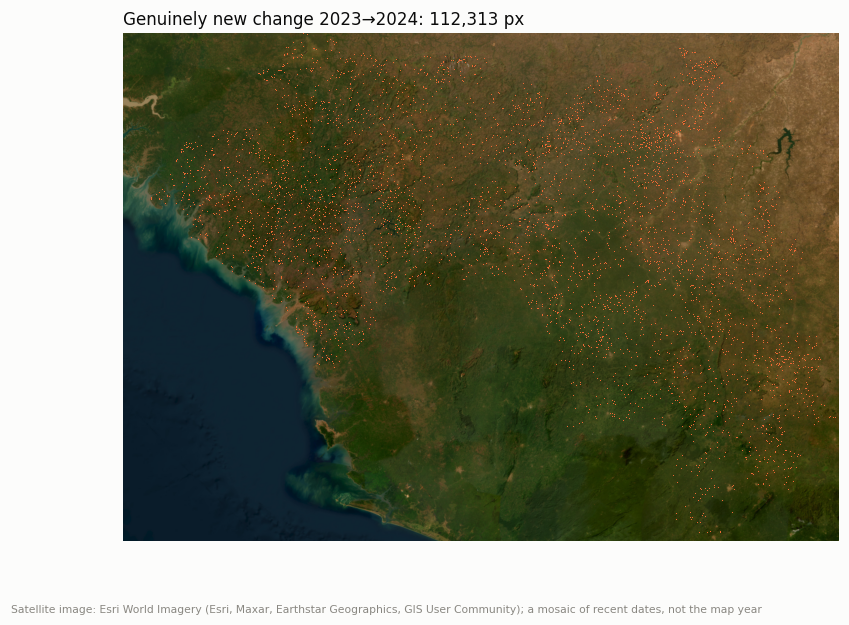

In [2]:
# Last year's genuinely new change, as the 2024→2025 forecast sees it
new_last = E.new_change_map(2024)
b = E.esri_cached(2024)
fig, ax = plt.subplots(figsize=(8.5, 6))
H.plot_satellite(ax, prof)
ax.imshow(np.ma.masked_where(~(new_last & g), new_last.astype(np.uint8)), cmap=plt.matplotlib.colors.ListedColormap([H.SERIES[1]]),
          interpolation="nearest")
ax.set_title(f"Genuinely new change 2023→2024: {int((new_last & g).sum()):,} px", loc="left", color=H.INK, fontsize=11)
H.satellite_credit(fig)
plt.show()

Last year's genuinely new change is spread across the country as small patches. The
features tell each transition's model how much of it, into the same destination class, lies
within 750 m, 2.5 km and 5 km of a pixel.

## 2 · Results

In [3]:
TAGS = {"Deployed method": ["R0c_guinea_dated", "R0c_guinea_dated_seed1", "R0c_guinea_dated_seed2"],
        "Deployed + contagion": ["contagion", "contagion_seed1", "contagion_seed2"]}
for tag, seed in (("contagion", 42), ("contagion_seed1", 1), ("contagion_seed2", 2)):
    for ph in PH:
        get(tag, ph, lambda ph=ph, tag=tag, seed=seed: E.run_deployed(ph, "guinea", "dated", "start", tag=tag, seed=seed,
                                                                      transition_features=E.contagion_features))
both = lambda y, t, m: np.vstack([E.contagion_features(y, t, m), ES.seasonal_features(y, t, m)])
for ph in PH:
    get("contagion_seasonal", ph, lambda ph=ph: E.run_deployed(ph, "guinea", "dated", "start", tag="contagion_seasonal",
                                                               transition_features=both))


def table_row(name, tags):
    sc = {ph: [kinds(t_, ph) for t_ in tags] for ph in PH}
    mean = lambda ph, f: np.mean([f(x) for x in sc[ph]])
    return {"Configuration": name if len(tags) == 1 else f"{name} (mean of {len(tags)} seeds)",
            "FoM % 2023→2024": mean("validation", lambda x: x["FoM"]), "FoM % 2024→2025": mean("test", lambda x: x["FoM"]),
            "± across seeds (2024→2025)": (max(x["FoM"] for x in sc["test"]) - min(x["FoM"] for x in sc["test"])) / 2
                                          if len(tags) > 1 else np.nan,
            "Check: new-change FoM % 2023→2024": mean("validation", lambda x: x["new"]["FoM"]),
            "Check: new-change FoM % 2024→2025": mean("test", lambda x: x["new"]["FoM"])}


floor = {}
for ph in PH:
    _, ts, tf = E.phase_years(ph)
    b_, c_ = E.esri_cached(ts), E.esri_cached(tf)
    dep = predicted("R0c_guinea_dated", ph)
    floor[ph] = np.mean([E.change_kind_scores(ts, c_, E.random_like(b_, dep, g & E.valid_classes(b_, c_, dep), seed=s), g)["FoM"]
                         for s in range(3)])
v, t, cv = "FoM % 2023→2024", "FoM % 2024→2025", "Check: new-change FoM % 2023→2024"
half_range = lambda xs: (max(xs) - min(xs)) / 2
spread = {ph: max(half_range([kinds(tg, ph)["FoM"] for tg in tags]) for tags in TAGS.values()) for ph in PH}
spread_new = {ph: max(half_range([kinds(tg, ph)["new"]["FoM"] for tg in tags]) for tags in TAGS.values()) for ph in PH}


def judge(frame):
    """The rule, row by row against the first row (the deployed method), plus the random floor."""
    ref = frame.iloc[0]

    def verdict(r):
        if r.name == 0:
            return "reference"
        if r[v] - ref[v] <= spread["validation"]:
            return "not chosen: no gain on 2023→2024"
        if r[cv] < ref[cv] - spread_new["validation"]:
            return "not chosen: fails the flip-back check"
        return "improves" if r[t] - ref[t] > spread["test"] else "chosen, but no gain on 2024→2025"

    frame["Against the rule"] = frame.apply(verdict, axis=1)
    frame["× random 2024→2025"] = frame[t] / floor["test"]
    frame.loc[len(frame)] = {"Configuration": "Random placement (mean of 3 draws)", v: floor["validation"], t: floor["test"],
                             "Against the rule": "floor", "× random 2024→2025": 1.0}
    return frame


results = judge(pd.DataFrame([table_row(n, tags) for n, tags in TAGS.items()]
                             + [table_row("Deployed + seasonal (seed 42, notebook 07)", ["S1_seasonal"]),
                                table_row("Deployed + contagion + seasonal (seed 42)", ["contagion_seasonal"])]))
print(f"Spread across seeds (largest of the two models): ±{spread['validation']:.2f} (2023→2024), ±{spread['test']:.2f} (2024→2025)")
H.show(results)

Spread across seeds (largest of the two models): ±0.06 (2023→2024), ±0.06 (2024→2025)


Configuration,FoM % 2023→2024,FoM % 2024→2025,± across seeds (2024→2025),Check: new-change FoM % 2023→2024,Check: new-change FoM % 2024→2025,Against the rule,× random 2024→2025
Deployed method (mean of 3 seeds),15.58,19.07,0.02,8.84,7.39,reference,2.19
Deployed + contagion (mean of 3 seeds),16.62,19.93,0.06,9.73,7.59,improves,2.29
"Deployed + seasonal (seed 42, notebook 07)",17.45,18.42,,9.84,7.72,"chosen, but no gain on 2024→2025",2.11
Deployed + contagion + seasonal (seed 42),18.05,19.14,,10.28,8.01,improves,2.20
Random placement (mean of 3 draws),5.11,8.71,,,,floor,1.00


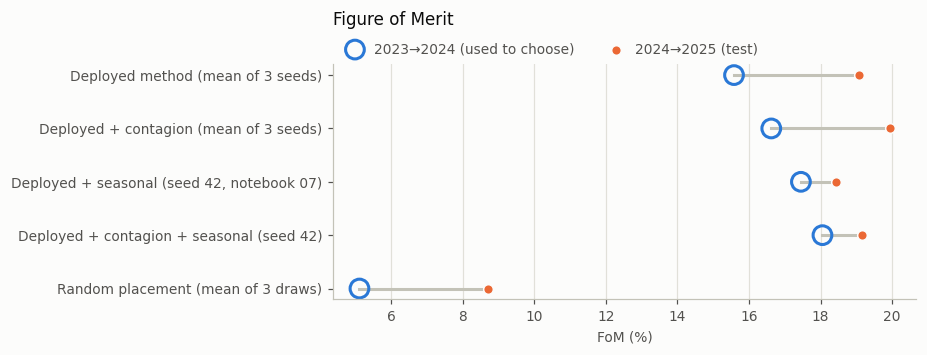

In [4]:
plot = results.rename(columns={v: "a", t: "b"})
H.plot_dumbbell(plot, "Figure of Merit", left="a", right="b",
                labels=("2023→2024 (used to choose)", "2024→2025 (test)"), xlabel="FoM (%)")
plt.tight_layout(); plt.show()

* **Contagion features pass the rule:** +1.04 points on 2023→2024 and +0.86 on 2024→2025
  (means of 3 seeds; the spread across seeds is about ±0.06). They also pass the flip-back
  check: more genuinely new change in both years (new-change FoM 9.73% and 7.59%, against 8.84%
  and 7.39%).
* **Combined with the seasonal features of notebook 07:** the best score on 2023→2024 in this
  section (18.05%), but only 19.14% on 2024→2025 (+0.07, one seed). As in notebook 07, the
  seasonal features help on the year used to choose and not on the test year.
* The contagion idea came from a diagnostic on 2024→2025 (notebook 06 section 7), so that year
  is not a fully independent test for it. 2025→2026 is.

## 3 · Does it fix the regional weakness?

The same multiple-resolution comparison as notebook 06 (Pontius et al. 2004), on 2024→2025.

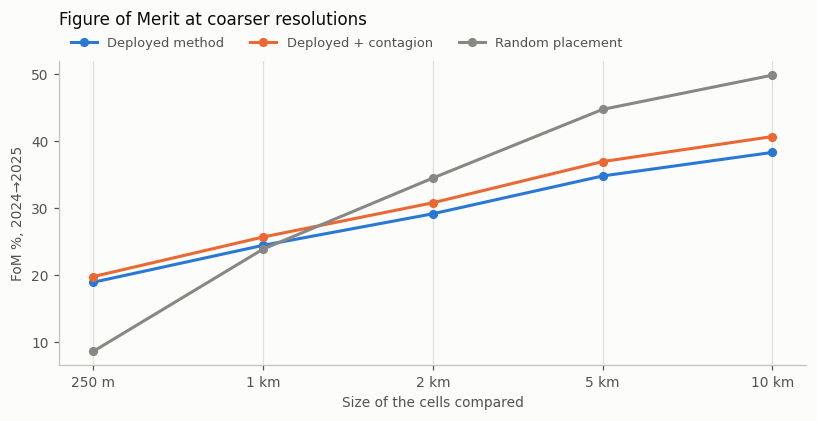

In [5]:
_, ts, tf = E.phase_years("test")
c = E.esri_cached(tf); b = E.esri_cached(ts)
km = {1: "250 m", 4: "1 km", 8: "2 km", 20: "5 km", 40: "10 km"}
dep = predicted("R0c_guinea_dated", "test")
maps_ = {"Deployed method": [predicted(t_, "test") for t_ in TAGS["Deployed method"]],
         "Deployed + contagion": [predicted(t_, "test") for t_ in TAGS["Deployed + contagion"]],
         "Random placement": [E.random_like(b, dep, g & E.valid_classes(b, c, dep), seed=s) for s in range(3)]}
resolution = pd.DataFrame({n: pd.DataFrame([E.fom_by_resolution(b, c, s, g, tuple(km)) for s in ms]).mean()
                           for n, ms in maps_.items()}).T
resolution.columns = list(km.values())
H.show(resolution.reset_index(names="Configuration"))

fig, ax = plt.subplots(figsize=(7.5, 3.9))
for colour, n in zip([H.SERIES[0], H.SERIES[1], H.MUTED], resolution.index):
    ax.plot(resolution.columns, resolution.loc[n], color=colour, linewidth=2, marker="o", markersize=5, label=n)
H.style_axes(ax)
ax.set_xlabel("Size of the cells compared", color=H.INK_2)
ax.set_ylabel("FoM %, 2024→2025", color=H.INK_2)
ax.set_title("Figure of Merit at coarser resolutions", loc="left", color=H.INK, fontsize=11, pad=24)
ax.legend(frameon=False, fontsize=8.5, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), labelcolor=H.INK_2)
plt.tight_layout(); plt.show()

* The contagion features raise the score at every cell size, most at 5 and 10 km (+2.1 and
  +2.4 points): they add regional information, as intended.
* From 2 km on the forecast is still below random placement (30.8% against 34.5% at 2 km). The
  regional weakness is smaller.

## 4 · A second model: logistic regression, from the tool comparison

Notebook 09 runs other land-change tools approach on the same data. Given the same amount of change and
our allocator, MOLUSCE's logistic regression placed change slightly better than the deployed
Random Forest (19.8% against 19.1% on 2024→2025). Logistic regression is also the suitability
model of CLUE-S and of many published applications (Verburg et al. 2002; Pontius et al. 2008).
It is tested here under the same rule, in two forms:

* **Logistic regression:** the deployed method with its Random Forest replaced by a
  logistic regression on the same, standardised features (`E.run_deployed(..., learner="logistic")`).
* **Averaged with the Random Forest:** the two models' suitabilities are rank-averaged with
  equal weight (`E.run_average`), as notebook 06 averaged the history models. Averaging models
  that make different errors is a standard way to improve predictions (Dietterich 2000). The
  weight is fixed at 0.5, not tuned.

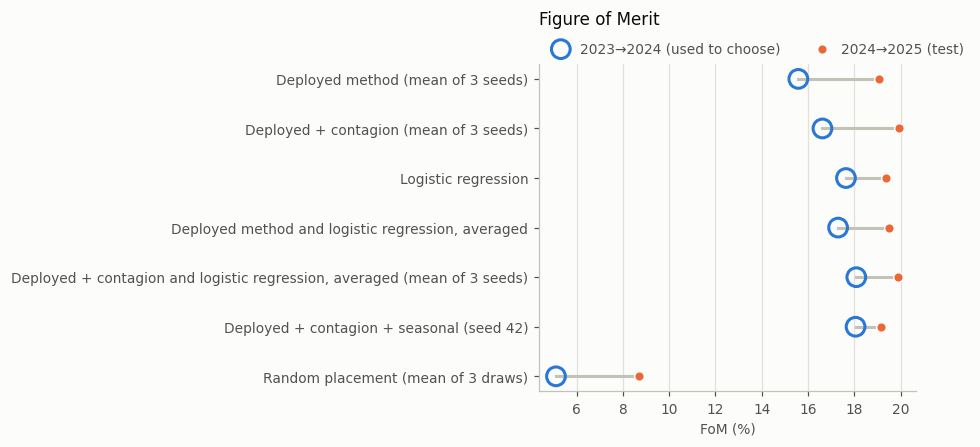

"Configuration (2024→2025, coarser cells)",250 m,1 km,2 km,5 km,10 km
Deployed method,18.94,24.46,29.18,34.83,38.35
Deployed + contagion,19.79,25.70,30.82,36.97,40.72
"Deployed + contagion and logistic regression, averaged",19.74,24.46,28.87,34.51,38.01


In [6]:
lr = {ph: get("logistic", ph, lambda ph=ph: E.run_deployed(ph, "guinea", "dated", "start", tag="logistic", learner="logistic"))
      for ph in PH}
LR_ATLAS = lambda ph: E.atlas_from(E.RUNS / "logistic" / ph / "surfaces", "expander")
AVERAGES = {"deployed_logistic": "R0c_guinea_dated", "contagion_logistic": "contagion",
            "contagion_logistic_seed1": "contagion_seed1", "contagion_logistic_seed2": "contagion_seed2"}
for tag, rf_tag in AVERAGES.items():
    for ph in PH:
        get(tag, ph, lambda ph=ph, tag=tag, rf_tag=rf_tag: E.run_average(
            tag, ph, E.atlas_from(E.RUNS / rf_tag / ph / "surfaces", "expander"), LR_ATLAS(ph)))
CHOSEN = ["contagion_logistic", "contagion_logistic_seed1", "contagion_logistic_seed2"]
models = judge(pd.DataFrame([table_row(n, tags) for n, tags in TAGS.items()] + [
    table_row("Logistic regression", ["logistic"]),
    table_row("Deployed method and logistic regression, averaged", ["deployed_logistic"]),
    table_row("Deployed + contagion and logistic regression, averaged", CHOSEN),
    table_row("Deployed + contagion + seasonal (seed 42)", ["contagion_seasonal"])]))
H.show(models)
plot = models.rename(columns={v: "a", t: "b"})
H.plot_dumbbell(plot, "Figure of Merit", left="a", right="b",
                labels=("2023→2024 (used to choose)", "2024→2025 (test)"), xlabel="FoM (%)")
plt.tight_layout(); plt.show()

resolution2 = pd.DataFrame({n: pd.DataFrame([E.fom_by_resolution(b, c, predicted(t_, "test"), g, tuple(km)) for t_ in tags]).mean()
                            for n, tags in {**TAGS, "Deployed + contagion and logistic regression, averaged": CHOSEN}.items()}).T
resolution2.columns = list(km.values())
H.show(resolution2.reset_index(names="Configuration (2024→2025, coarser cells)"))

* **Logistic regression alone passes the rule:** 17.64% on 2023→2024 and 19.36% on 2024→2025,
  against 15.58% and 19.07% for the deployed method. On 2023→2024 it beats the Random Forest by
  2 points.
* **Averaged with the Random Forest it does better:** 17.30% and 19.48% for the deployed
  method; with contagion features, 18.08% and 19.87% (3 seeds, ±0.04).
* **Choosing on 2023→2024:** deployed + contagion averaged with logistic regression (18.08%) and
  deployed + contagion + seasonal (18.05%, one seed) are tied within the seed spread. The first
  needs no new data and is confirmed over three seeds, and seasonal features failed on their own
  (notebook 07), so it is the one chosen. On 2024→2025 it scores **19.87%, +0.80 over the
  deployed method, 2.3 times random placement**.
* It passes the flip-back check: new-change FoM 9.78% and 7.75%, against 8.84% and 7.39%.
* Contagion alone scores slightly higher on 2024→2025 (19.93%), but the choice is made on
  2023→2024, where the average is clearly ahead (18.08% against 16.62%). Picking by the test
  year would make it no longer a test.
* At coarser cells the average falls back to the deployed method's level (24.5% at 1 km),
  below contagion alone: logistic regression adds precision at the pixel, the Random Forest
  with contagion carries more of the regional pattern.

In [7]:
# Sensitivity to the weight, which is fixed at 0.5 and not tuned: the chosen average with 0.25 and 0.75 on the
# Random Forest (seed 42), to show the result does not hinge on it.
for w in (0.25, 0.75):
    for ph in PH:
        get(f"contagion_logistic_w{int(100 * w)}", ph, lambda ph=ph, w=w: E.run_average(
            f"contagion_logistic_w{int(100 * w)}", ph, E.atlas_from(E.RUNS / "contagion" / ph / "surfaces", "expander"), LR_ATLAS(ph), w))
weights = pd.DataFrame([{"Weight on the Random Forest (rest on the logistic regression)": w, v: kinds(tag, "validation")["FoM"],
                         t: kinds(tag, "test")["FoM"], "Check: new-change FoM % 2024→2025": kinds(tag, "test")["new"]["FoM"]}
                        for w, tag in ((0.25, "contagion_logistic_w25"), (0.5, "contagion_logistic"), (0.75, "contagion_logistic_w75"))])
weights.round(3).to_csv(H.SUMMARY / "08_weights.csv", index=False)
H.show(weights)

[contagion_logistic_w25/validation] FoM 18.20


[contagion_logistic_w25/test] FoM 19.71


[contagion_logistic_w75/validation] FoM 17.57


[contagion_logistic_w75/test] FoM 20.07


Weight on the Random Forest (rest on the logistic regression),FoM % 2023→2024,FoM % 2024→2025,Check: new-change FoM % 2024→2025
0.25,18.20,19.71,7.76
0.50,18.11,19.93,7.78
0.75,17.57,20.07,7.78


**Reading:** the weight is fixed at 0.5, not tuned: a simple average of forecasts is hard to beat
with estimated weights (Clemen 1989; Smith & Wallis 2009). Changing it to 0.25 or 0.75 moves the
score by up to 0.54 points on 2023→2024 and 0.22 on 2024→2025 (seed 42). 0.25 is slightly ahead on
2023→2024 (18.20% against 18.11%) and 0.75 on 2024→2025 (20.07% against 19.93%), so no weight is
best in both years. Every weight beats the deployed method in both years (15.58% and 19.07%) and
keeps the new-change FoM at 7.8%. The result does not hinge on the weight; 0.5 stays.

## Summary

| On 2024→2025 (test) | Figure of Merit | × random | Against the rule |
|---|---:|---:|---|
| Deployed method (mean of 3 seeds) | 19.07% | 2.2 | reference |
| Deployed + contagion (mean of 3 seeds) | 19.93% | 2.3 | improves |
| Logistic regression | 19.36% | 2.2 | improves |
| Deployed + contagion + seasonal (seed 42) | 19.14% | 2.2 | improves, barely (+0.07) |
| **Deployed + contagion, averaged with logistic regression** (mean of 3 seeds) | **19.87%** | **2.3** | **improves; chosen on 2023→2024** |
| Random placement | 8.71% | 1.0 | floor |

* **Contagion features improve the deployed method in both years**, using only the ESRI maps
  it already downloads.
* **Logistic regression, the model of MOLUSCE and CLUE-S, also improves it**, and averaging it
  with the Random Forest gives the best score on the year used to choose.
* **The weight does not matter much:** 0.25 or 0.75 on the Random Forest instead of 0.5 gives
  19.71–20.07% on 2024→2025, all above the deployed method; 0.5 stays.
* **Recommendation:** the deployed method with corrected inputs plus contagion features,
  averaged with a logistic regression. No new data, under two minutes more training per year.
  Confirm on 2025→2026 when ESRI publishes its 2026 map.

### References

* Bouthillier, X., Delaunay, P., Bronzi, M., et al. (2021). Accounting for variance in
  machine learning benchmarks. *Proceedings of Machine Learning and Systems* 3.
* Clemen, R.T. (1989). Combining forecasts: a review and annotated bibliography. *International
  Journal of Forecasting* 5(4), 559–583.
* Dietterich, T.G. (2000). Ensemble methods in machine learning. In *Multiple Classifier
  Systems*, Lecture Notes in Computer Science 1857, 1–15.
* Pontius, R.G. Jr., Huffaker, D., Denman, K. (2004). Useful techniques of validation for
  spatially explicit land-change models. *Ecological Modelling* 179(4), 445–461.
* Pontius, R.G. Jr., Boersma, W., Castella, J.-C., et al. (2008). Comparing the input,
  output, and validation maps for several models of land change. *Annals of Regional Science* 42(1), 11–37.
* Rosa, I.M.D., Purves, D., Souza, C. Jr., Ewers, R.M. (2013). Predictive modelling of
  contagious deforestation in the Brazilian Amazon. *PLoS ONE* 8(10), e77231.
* Smith, J., Wallis, K.F. (2009). A simple explanation of the forecast combination puzzle. *Oxford
  Bulletin of Economics and Statistics* 71(3), 331–355.
* Verburg, P.H., Soepboer, W., Veldkamp, A., Limpiada, R., Espaldon, V., Mastura, S.S.A. (2002).
  Modeling the spatial dynamics of regional land use: the CLUE-S model. *Environmental
  Management* 30(3), 391–405.

In [8]:
H.SUMMARY.mkdir(parents=True, exist_ok=True)
results.round(3).to_csv(H.SUMMARY / "08_contagion.csv", index=False)
models.round(3).to_csv(H.SUMMARY / "08_models.csv", index=False)
resolution.round(3).to_csv(H.SUMMARY / "08_resolution.csv")
print("Saved tables to", H.SUMMARY.relative_to(H.ROOT))

Saved tables to outputs\summary
